In [14]:
import torch
import torch.nn as nn
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler  # <--- Importante

# 1. Carrega o dataset Iris
iris = load_iris()
X = iris.data    
y = iris.target  

# 2. Divide em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Aplica o StandardScaler nos dados do Scikit-Learn
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Ajusta e transforma o treino
X_test_scaled = scaler.transform(X_test)        # Apenas transforma o teste

# 4. Converte os dados já padronizados para tensores do PyTorch
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# 5. Define a função de erro (continua sendo a mesma para multiclasse)
loss_fn = nn.CrossEntropyLoss()

print("Dados padronizados com sucesso e prontos para a rede neural!")



Dados padronizados com sucesso e prontos para a rede neural!


In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class IrisClassifier(nn.Module):
    def __init__(self):
        super(IrisClassifier, self).__init__()
        
        # Camada 1: Entrada (4 características) -> Camada Oculta (16 neurônios)
        self.fc1 = nn.Linear(in_features=4, out_features=16)
        
        # Camada 2: Camada Oculta (16) -> Outra Camada Oculta (8 neurônios)
        self.fc2 = nn.Linear(in_features=16, out_features=8)
        
        # Camada 3: Saída (8) -> Classes (3 neurônios para as 3 espécies)
        self.fc3 = nn.Linear(in_features=8, out_features=3)
        
    def forward(self, x):
        # Passa os dados pelas camadas aplicando a função de ativação ReLU
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        
        # Na última camada, retornamos os valores brutos (logits).
        # Não usamos Softmax aqui porque o nn.CrossEntropyLoss já faz isso internamente!
        x = self.fc3(x)
        return x

# Instancia o modelo
model = IrisClassifier()
print(model)


IrisClassifier(
  (fc1): Linear(in_features=4, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=8, bias=True)
  (fc3): Linear(in_features=8, out_features=3, bias=True)
)


In [16]:
# ==========================================
# SEU PASSO A PASSO PARA VERIFICAR O ERRO
# ==========================================

# 1. Instancie a função de erro adequada para o Iris
loss_fn = nn.CrossEntropyLoss()

# 2. Crie dados fictícios para testar (Simulando um batch de 3 flores)
# Lembre-se: Entrada precisa ter 4 colunas (features) padronizadas
dados_de_teste = torch.tensor([
    [ 0.5, -1.2,  1.1,  0.3],  # Flor 1
    [-0.8,  0.9, -0.4, -1.1],  # Flor 2
    [ 1.2,  0.1,  0.9,  1.4]   # Flor 3
], dtype=torch.float32)

# Rótulos reais dessas 3 flores (Ex: classe 0, classe 2 e classe 1)
# O tipo precisa ser 'long' para a CrossEntropyLoss
rotulos_reais = torch.tensor([0, 2, 1], dtype=torch.long)

# 3. Passe os dados pelo seu modelo para obter os palpites (logits)
palpites_do_modelo = model(dados_de_teste)

# 4. Calcule o erro final!
erro_calculado = loss_fn(palpites_do_modelo, rotulos_reais)

# --- Exibindo os resultados para você verificar ---
print("\n--- Verificação do Erro ---")
print("Palpites brutos do seu modelo (Logits):\n", palpites_do_modelo)
print("\nValor do erro (Loss):", erro_calculado.item())



--- Verificação do Erro ---
Palpites brutos do seu modelo (Logits):
 tensor([[ 1.4466e-01, -1.6083e-01,  7.4165e-01],
        [ 1.6642e-01, -1.9412e-01,  4.7570e-01],
        [ 2.7383e-01, -3.2091e-04,  6.8368e-01]], grad_fn=<AddmmBackward0>)

Valor do erro (Loss): 1.1783063411712646


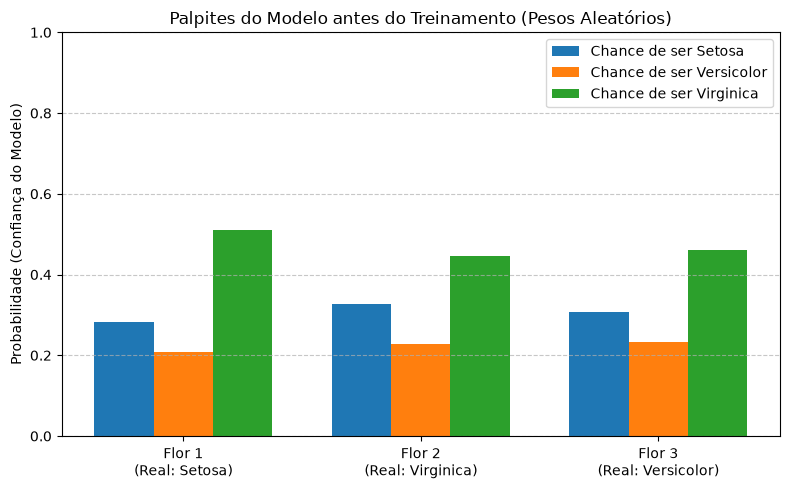

In [17]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Aplicamos o Softmax para transformar os logits brutos em probabilidades (0 a 1)
probabilidades = F.softmax(palpites_do_modelo, dim=1).detach().numpy()

# 2. Configuração das barras do gráfico
classes = ['Setosa (0)', 'Versicolor (1)', 'Virginica (2)']
flores = ['Flor 1\n(Real: Setosa)', 'Flor 2\n(Real: Virginica)', 'Flor 3\n(Real: Versicolor)']
x = np.arange(len(flores))
largura = 0.25

# 3. Cria o plot
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - largura, probabilidades[:, 0], largura, label='Chance de ser Setosa', color='#1f77b4')
ax.bar(x,           probabilidades[:, 1], largura, label='Chance de ser Versicolor', color='#ff7f0e')
ax.bar(x + largura, probabilidades[:, 2], largura, label='Chance de ser Virginica', color='#2ca02c')

# 4. Customização visual
ax.set_ylabel('Probabilidade (Confiança do Modelo)')
ax.set_title('Palpites do Modelo antes do Treinamento (Pesos Aleatórios)')
ax.set_xticks(x)
ax.set_xticklabels(flores)
ax.set_ylim(0, 1) # Limita o eixo Y de 0% a 100%
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()


In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.datasets import load_iris
from sklearn.datasets import load_digits
from sklearn.model_selection import StratifiedKFold  # <--- Mudou aqui
from sklearn.preprocessing import StandardScaler
import numpy as np

# 1. PREPARAÇÃO DOS DADOS REAIS
D = load_iris()
X, y = iris.data, iris.target

# Definindo a rede neural (mesma estrutura que você criou)
class IrisClassifier(nn.Module):
    def __init__(self):
        super(IrisClassifier, self).__init__()
        self.fc1 = nn.Linear(4, 16)
        self.fc2 = nn.Linear(16, 8)
        self.fc3 = nn.Linear(8, 3)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# CONFIGURAÇÃO DO K-FOLD ESTRATIFICADO
k_folds = 5
skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

acuracias_dos_folds = []

print(f"Iniciando Validação Cruzada Estratificada com {k_folds} Folds...\n")

# O loop vai rodar 5 vezes. A cada vez, o treino/teste muda de forma estratificada
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    
    # Separa os dados usando os índices do K-Fold
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Aplica o StandardScaler dentro de cada Fold (Boa prática!)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Converte para Tensores
    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)
    
    # Reinicia o modelo e o otimizador para cada fold começar do zero
    model = IrisClassifier()
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.01)
    
    # LOOP DE TREINAMENTO DO FOLD ATUAL
    for epoch in range(150):
        model.train()
        optimizer.zero_grad()
        palpites_treino = model(X_train_tensor)
        loss = loss_fn(palpites_treino, y_train_tensor)
        loss.backward()
        optimizer.step()
        
    # VALIDAÇÃO DO FOLD ATUAL
    model.eval()
    with torch.no_grad():
        palpites_teste = model(X_test_tensor)
        previsoes = torch.argmax(palpites_teste, dim=1)
        acertos = (previsoes == y_test_tensor).sum().item()
        acuracia = (acertos / len(y_test_tensor)) * 100
        acuracias_dos_folds.append(acuracia)
        
    print(f"Fold {fold + 1} Concluído -> Acurácia no Teste: {acuracia:.2f}% | Loss de Treino: {loss.item():.4f}")

# RESULTADO FINAL DA VALIDAÇÃO CRUZADA
print("\n--- RESULTADO FINAL DO K-FOLD ---")
print(f"Acurácias obtidas por fold: {acuracias_dos_folds}")
print(f"Média Final de Acurácia: {np.mean(acuracias_dos_folds):.2f}%")


Iniciando Validação Cruzada Estratificada com 5 Folds...

Fold 1 Concluído -> Acurácia no Teste: 100.00% | Loss de Treino: 0.0432
Fold 2 Concluído -> Acurácia no Teste: 96.67% | Loss de Treino: 0.0362
Fold 3 Concluído -> Acurácia no Teste: 90.00% | Loss de Treino: 0.0048
Fold 4 Concluído -> Acurácia no Teste: 100.00% | Loss de Treino: 0.0416
Fold 5 Concluído -> Acurácia no Teste: 90.00% | Loss de Treino: 0.0820

--- RESULTADO FINAL DO K-FOLD ---
Acurácias obtidas por fold: [100.0, 96.66666666666667, 90.0, 100.0, 90.0]
Média Final de Acurácia: 95.33%


Iniciando K-Fold Estratificado com 5 Folds (Batch Size = 32)...

Fold 1 Concluído -> Acurácia no Teste: 96.39% | Loss Final de Treino: 0.0001
Fold 2 Concluído -> Acurácia no Teste: 98.61% | Loss Final de Treino: 0.0001
Fold 3 Concluído -> Acurácia no Teste: 97.21% | Loss Final de Treino: 0.0001
Fold 4 Concluído -> Acurácia no Teste: 96.38% | Loss Final de Treino: 0.0001
Fold 5 Concluído -> Acurácia no Teste: 97.21% | Loss Final de Treino: 0.0001

--- RESULTADO FINAL DO K-FOLD ---
Média Final de Acurácia: 97.16%

--- MATRIZ DE CONFUSÃO (SOMA DOS 5 FOLDS) ---
[[177   0   0   0   0   0   1   0   0   0]
 [  0 177   0   0   1   0   2   0   2   0]
 [  0   0 174   2   0   0   0   0   1   0]
 [  0   0   0 177   0   1   0   1   0   4]
 [  0   1   0   0 178   0   0   0   1   1]
 [  0   0   0   1   1 174   1   0   2   3]
 [  1   2   0   0   0   0 178   0   0   0]
 [  0   2   0   0   1   0   0 175   0   1]
 [  1   7   0   0   0   1   1   0 164   0]
 [  0   0   0   3   0   2   0   2   1 172]]


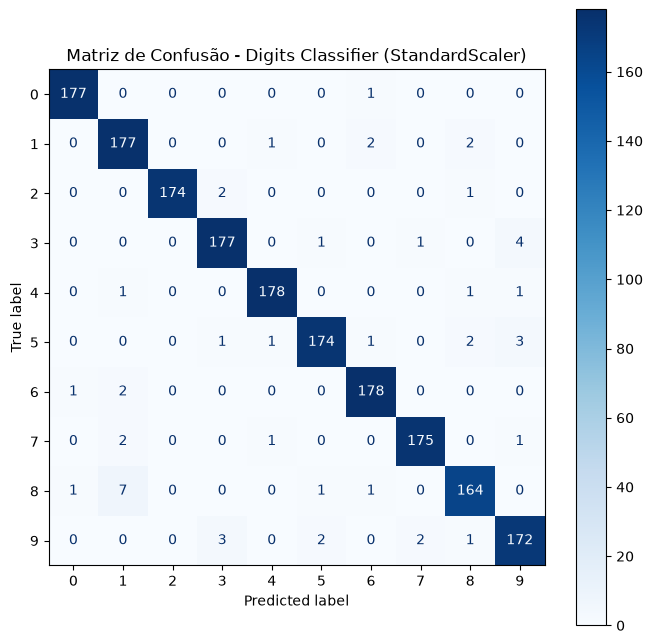

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler  # <--- Alterado para StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# 1. PREPARAÇÃO DOS DADOS REAIS (Digits)
digits = load_digits()
X, y = digits.data, digits.target

# 2. DEFINIÇÃO DA REDE NEURAL
class DigitsClassifier(nn.Module):
    def __init__(self):
        super(DigitsClassifier, self).__init__()
        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 10)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# 3. CONFIGURAÇÕES
k_folds = 5
batch_size = 32
max_epochs = 50

skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)
acuracias_dos_folds = []

# LISTAS PARA ACUMULAR OS RÓTULOS REAIS E AS PREVISÕES DE TODOS OS FOLDS
todas_as_meta_reais = []
todas_as_previsoes = []

print(f"Iniciando K-Fold Estratificado com {k_folds} Folds (Batch Size = {batch_size})...\n")

# 4. LOOP DOS FOLDS
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Normalização com StandardScaler
    scaler = StandardScaler()  # <--- Alterado para StandardScaler
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)
    
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    model = DigitsClassifier()
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.005)
    
    # TREINAMENTO
    for epoch in range(max_epochs):
        model.train()
        running_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            palpites = model(batch_x)
            loss = loss_fn(palpites, batch_y)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * batch_x.size(0)
            
        epoch_loss = running_loss / len(train_dataset)
        
    # VALIDAÇÃO DO FOLD ATUAL
    model.eval()
    with torch.no_grad():
        palpites_teste = model(X_test_tensor)
        previsoes = torch.argmax(palpites_teste, dim=1).cpu().numpy()
        
        todas_as_meta_reais.extend(y_test)
        todas_as_previsoes.extend(previsoes)
        
        acertos = (previsoes == y_test).sum()
        acuracia = (acertos / len(y_test)) * 100
        acuracias_dos_folds.append(acuracia)
        
    print(f"Fold {fold + 1} Concluído -> Acurácia no Teste: {acuracia:.2f}% | Loss Final de Treino: {epoch_loss:.4f}")

# RESULTADO FINAL E MATRIZ DE CONFUSÃO
print("\n--- RESULTADO FINAL DO K-FOLD ---")
print(f"Média Final de Acurácia: {np.mean(acuracias_dos_folds):.2f}%")

# 5. GERANDO A MATRIZ DE CONFUSÃO GERAL
cm = confusion_matrix(todas_as_meta_reais, todas_as_previsoes)

print("\n--- MATRIZ DE CONFUSÃO (SOMA DOS 5 FOLDS) ---")
print(cm)

# 6. EXIBIÇÃO GRÁFICA
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Matriz de Confusão - Digits Classifier (StandardScaler)")
plt.show()

In [20]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import load_digits
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import MinMaxScaler  # <--- Mudou aqui (MinMaxScaler)
import numpy as np

# 1. PREPARAÇÃO DOS DADOS REAIS (Digits)
digits = load_digits()
X, y = digits.data, digits.target  # X: 1797 amostras, 64 atributos (pixels) | y: classes de 0 a 9

# 2. DEFINIÇÃO DA REDE NEURAL (Ajustada para o Digits)
class DigitsClassifier(nn.Module):
    def __init__(self):
        super(DigitsClassifier, self).__init__()
        self.fc1 = nn.Linear(64, 32)  # 64 entradas -> 32 neurônios
        self.fc2 = nn.Linear(32, 16)  # 32 -> 16
        self.fc3 = nn.Linear(16, 10)  # 10 saídas (dígitos 0-9)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# 3. CONFIGURAÇÕES
k_folds = 5
batch_size = 32
max_epochs = 50

skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)
acuracias_dos_folds = []

print(f"Iniciando K-Fold Estratificado com {k_folds} Folds (Batch Size = {batch_size})...\n")

# 4. LOOP DOS FOLDS
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
    
    # Separação dos dados pelos índices do fold
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    # Normalização com MinMaxScaler (escala de 0 a 1)
    scaler = MinMaxScaler()  # <--- Mudou aqui
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Conversão para Tensores
    X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long)
    X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
    y_test_tensor = torch.tensor(y_test, dtype=torch.long)
    
    # Criando o DataLoader com BATCH SIZE = 32
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    # Reinicia o modelo e o otimizador para cada fold
    model = DigitsClassifier()
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.005)
    
    # LOOP DE TREINAMENTO COM MINI-BATCH
    for epoch in range(max_epochs):
        model.train()
        running_loss = 0.0
        
        for batch_x, batch_y in train_loader:
            optimizer.zero_grad()
            palpites = model(batch_x)
            loss = loss_fn(palpites, batch_y)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * batch_x.size(0)
            
        epoch_loss = running_loss / len(train_dataset)
        
    # VALIDAÇÃO DO FOLD ATUAL
    model.eval()
    with torch.no_grad():
        palpites_teste = model(X_test_tensor)
        previsoes = torch.argmax(palpites_teste, dim=1)
        acertos = (previsoes == y_test_tensor).sum().item()
        acuracia = (acertos / len(y_test_tensor)) * 100
        acuracias_dos_folds.append(acuracia)
        
    print(f"Fold {fold + 1} Concluído -> Acurácia no Teste: {acuracia:.2f}% | Loss Final de Treino: {epoch_loss:.4f}")

# RESULTADO FINAL
print("\n--- RESULTADO FINAL DO K-FOLD ---")
print(f"Acurácias obtidas por fold: {acuracias_dos_folds}")
print(f"Média Final de Acurácia: {np.mean(acuracias_dos_folds):.2f}%")

Iniciando K-Fold Estratificado com 5 Folds (Batch Size = 32)...

Fold 1 Concluído -> Acurácia no Teste: 96.39% | Loss Final de Treino: 0.0028
Fold 2 Concluído -> Acurácia no Teste: 96.67% | Loss Final de Treino: 0.0044
Fold 3 Concluído -> Acurácia no Teste: 95.26% | Loss Final de Treino: 0.0029
Fold 4 Concluído -> Acurácia no Teste: 96.94% | Loss Final de Treino: 0.0018
Fold 5 Concluído -> Acurácia no Teste: 97.21% | Loss Final de Treino: 0.0021

--- RESULTADO FINAL DO K-FOLD ---
Acurácias obtidas por fold: [96.38888888888889, 96.66666666666667, 95.26462395543176, 96.93593314763231, 97.21448467966573]
Média Final de Acurácia: 96.49%


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_digits
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

import matplotlib.pyplot as plt
import numpy as np

# 1. PREPARAÇÃO DOS DADOS REAIS (Digits)
digits = load_digits()
X, y = digits.data, digits.target

# 2. DEFINIÇÃO DA REDE NEURAL EM PYTORCH
class DigitsClassifier(nn.Module):
    def __init__(self):
        super(DigitsClassifier, self).__init__()
        self.fc1 = nn.Linear(64, 32)
        self.fc2 = nn.Linear(32, 16)
        self.fc3 = nn.Linear(16, 10)
        
    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

# 3. WRAPPER COMPATÍVEL COM SCIKIT-LEARN
class PyTorchDigitsClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, lr=0.005, batch_size=32, max_epochs=50):
        self.lr = lr
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        
    def fit(self, X, y):
        # Normalização isolada por fold dentro do fit
        self.scaler_ = StandardScaler()
        X_scaled = self.scaler_.fit_transform(X)
        
        # Conversão de Tensores e Dataloader
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
        y_tensor = torch.tensor(y, dtype=torch.long)
        
        dataset = TensorDataset(X_tensor, y_tensor)
        loader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)
        
        # Instanciação do modelo limpo para o fold
        self.model_ = DigitsClassifier()
        loss_fn = nn.CrossEntropyLoss()
        optimizer = optim.Adam(self.model_.parameters(), lr=self.lr)
        
        # Loop interno de treinamento
        for epoch in range(self.max_epochs):
            self.model_.train()
            for batch_x, batch_y in loader:
                optimizer.zero_grad()
                outputs = self.model_(batch_x)
                loss = loss_fn(outputs, batch_y)
                loss.backward()
                optimizer.step()
                
        self.classes_ = np.unique(y)
        return self

    def predict(self, X):
        self.model_.eval()
        X_scaled = self.scaler_.transform(X)
        X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
        
        with torch.no_grad():
            outputs = self.model_(X_tensor)
            preds = torch.argmax(outputs, dim=1).cpu().numpy()
            
        return preds

# 4. CONFIGURAÇÃO DO K-FOLD E ESTIMADOR
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
estimator = PyTorchDigitsClassifier(lr=0.005, batch_size=32, max_epochs=50)

print("Executando cross_validate do Scikit-Learn com modelo PyTorch...\n")

# 5. EXECUÇÃO DO CROSS_VALIDATE
cv_results = cross_validate(estimator, X, y, cv=skf, scoring='accuracy', return_train_score=False)
acuracias = cv_results['test_score'] * 100

print("--- RESULTADO DO CROSS_VALIDATE ---")
for fold, acc in enumerate(acuracias, 1):
    print(f"Fold {fold} -> Acurácia no Teste: {acc:.2f}%")
print(f"Média Final de Acurácia: {np.mean(acuracias):.2f}%\n")

# 6. OBTENÇÃO DAS PREVISÕES FORA DA AMOSTRA PARA A MATRIZ DE CONFUSÃO
previsoes_cv = cross_val_predict(estimator, X, y, cv=skf)

# 7. RELATÓRIO E MATRIZ DE CONFUSÃO (%)
print("--- RELATÓRIO DE PRECISÃO POR CLASSE ---")
print(classification_report(y, previsoes_cv, digits=2))

cm_percent = confusion_matrix(y, previsoes_cv, normalize='true') * 100

fig, ax = plt.subplots(figsize=(9, 9))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_percent, display_labels=np.arange(10))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='.1f')
plt.title("Matriz de Confusão Normalizada (%) via cross_val_predict")
plt.xlabel("Classe Prevista")
plt.ylabel("Classe Real")
plt.show()